# Redes Neuronales III — Laboratorio A
## Datos, preprocesamiento y modelo baseline (MNIST)

**Objetivo:** construir una línea base reproducible sobre MNIST con partición
Train / Dev / Test estratificada, normalización y un modelo denso simple.

**Entregables:**
- Formas de Train, Dev y Test
- Tabla de distribución de clases
- `model.summary()` del baseline
- Curvas de Loss y Accuracy (Train vs Dev)

In [14]:
# ============================================================
# Paso 1. Importar herramientas y fijar semillas
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers, callbacks

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("Semilla fijada en:", SEED)

TensorFlow: 2.21.0
NumPy: 2.1.3
Semilla fijada en: 42


In [15]:
# ============================================================
# Paso 2. Cargar MNIST
# ============================================================
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.mnist.load_data()

print("Train original:", x_train_full.shape, y_train_full.shape)
print("Test:          ", x_test.shape, y_test.shape)
print("Tipo de dato:  ", x_train_full.dtype)
print("Rango píxeles: ", x_train_full.min(), "-", x_train_full.max())

Train original: (60000, 28, 28) (60000,)
Test:           (10000, 28, 28) (10000,)
Tipo de dato:   uint8
Rango píxeles:  0 - 255


In [16]:
# ============================================================
# Paso 3. Crear Train y Dev de forma estratificada
# ============================================================
x_train, x_dev, y_train, y_dev = train_test_split(
    x_train_full, y_train_full,
    test_size=0.20,
    random_state=SEED,
    stratify=y_train_full
)

print("Train:", x_train.shape, y_train.shape)
print("Dev:  ", x_dev.shape,   y_dev.shape)
print("Test: ", x_test.shape,  y_test.shape)

Train: (48000, 28, 28) (48000,)
Dev:   (12000, 28, 28) (12000,)
Test:  (10000, 28, 28) (10000,)


In [17]:
# ============================================================
# Paso 4. Normalizar los píxeles a [0, 1]
# ============================================================
x_train = x_train.astype("float32") / 255.0
x_dev   = x_dev.astype("float32")   / 255.0
x_test  = x_test.astype("float32")  / 255.0

print("Rango train:", x_train.min(), "-", x_train.max())
print("Rango dev:  ", x_dev.min(),   "-", x_dev.max())
print("Rango test: ", x_test.min(),  "-", x_test.max())
print("dtype train:", x_train.dtype)

Rango train: 0.0 - 1.0
Rango dev:   0.0 - 1.0
Rango test:  0.0 - 1.0
dtype train: float32


In [18]:
# ============================================================
# Paso 5. Verificar la distribución de clases
# ============================================================
def distribution_classes(y, nombre):
    """Devuelve y muestra una tabla con la distribución de clases."""
    conteos = np.bincount(y, minlength=10)
    porcentajes = conteos / len(y) * 100
    tabla = pd.DataFrame({
        "digito": np.arange(10),
        "cantidad": conteos,
        "porcentaje": np.round(porcentajes, 2)
    })
    print(f"\n=== {nombre} (n = {len(y)}) ===")
    display(tabla)
    return tabla

dist_train = distribution_classes(y_train, "TRAIN")
dist_dev   = distribution_classes(y_dev,   "DEV")
dist_test  = distribution_classes(y_test,  "TEST")


=== TRAIN (n = 48000) ===


,digito,cantidad,porcentaje
0,0,4738,9.87
1,1,5394,11.24
2,2,4766,9.93
3,3,4905,10.22
4,4,4674,9.74
5,5,4337,9.04
6,6,4734,9.86
7,7,5012,10.44
8,8,4681,9.75
9,9,4759,9.91



=== DEV (n = 12000) ===


,digito,cantidad,porcentaje
0,0,1185,9.88
1,1,1348,11.23
2,2,1192,9.93
3,3,1226,10.22
4,4,1168,9.73
5,5,1084,9.03
6,6,1184,9.87
7,7,1253,10.44
8,8,1170,9.75
9,9,1190,9.92



=== TEST (n = 10000) ===


,digito,cantidad,porcentaje
0,0,980,9.80
1,1,1135,11.35
2,2,1032,10.32
3,3,1010,10.10
4,4,982,9.82
5,5,892,8.92
6,6,958,9.58
7,7,1028,10.28
8,8,974,9.74
9,9,1009,10.09


In [19]:
# ============================================================
# Paso 6. Crear el modelo baseline
# ============================================================
def crear_modelo_baseline(units=128, learning_rate=0.001):
    """Modelo denso simple: Flatten -> Dense(relu) -> Dense(softmax)."""
    modelo = keras.Sequential([
        layers.Input(shape=(28, 28)),
        layers.Flatten(),
        layers.Dense(units, activation="relu"),
        layers.Dense(10, activation="softmax")
    ], name="baseline_mlp")

    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return modelo


modelo_base = crear_modelo_baseline()
modelo_base.summary()

Model: "baseline_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [20]:
# ============================================================
# Paso 7. Entrenar usando Dev explícito
# ============================================================
EPOCHS = 5
BATCH_SIZE = 64

hist_base = modelo_base.fit(
    x_train, y_train,
    validation_data=(x_dev, y_dev),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=1
)

Epoch 1/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9084 - loss: 0.3271 - val_accuracy: 0.9443 - val_loss: 0.1980
Epoch 2/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9555 - loss: 0.1550 - val_accuracy: 0.9560 - val_loss: 0.1516
Epoch 3/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9693 - loss: 0.1076 - val_accuracy: 0.9621 - val_loss: 0.1291
Epoch 4/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9763 - loss: 0.0814 - val_accuracy: 0.9640 - val_loss: 0.1209
Epoch 5/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9817 - loss: 0.0637 - val_accuracy: 0.9655 - val_loss: 0.1167


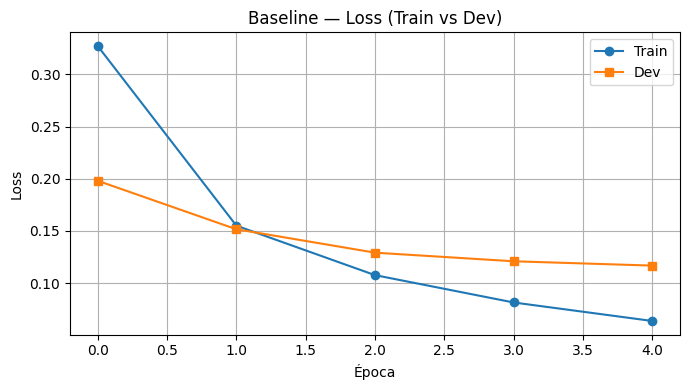

In [21]:
# ============================================================
# Paso 8a. Curva de Loss (Train vs Dev)
# ============================================================
plt.figure(figsize=(7, 4))
plt.plot(hist_base.history["loss"],     label="Train", marker="o")
plt.plot(hist_base.history["val_loss"], label="Dev",   marker="s")
plt.xlabel("Época")
plt.ylabel("Loss")
plt.title("Baseline — Loss (Train vs Dev)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

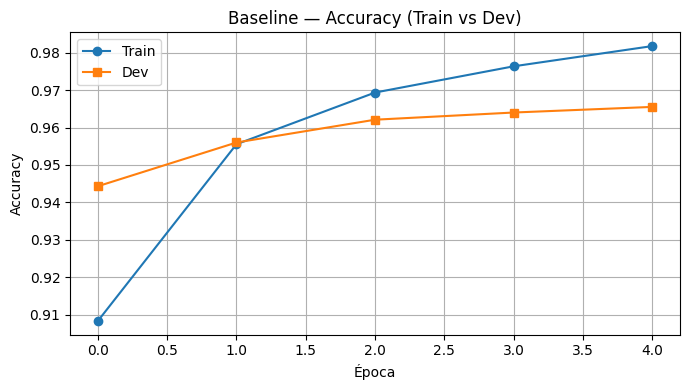

In [22]:
# ============================================================
# Paso 8b. Curva de Accuracy (Train vs Dev)
# ============================================================
plt.figure(figsize=(7, 4))
plt.plot(hist_base.history["accuracy"],     label="Train", marker="o")
plt.plot(hist_base.history["val_accuracy"], label="Dev",   marker="s")
plt.xlabel("Época")
plt.ylabel("Accuracy")
plt.title("Baseline — Accuracy (Train vs Dev)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [23]:
# ============================================================
# Resumen numérico del baseline
# ============================================================
resumen_base = pd.DataFrame({
    "epoca":        np.arange(1, EPOCHS + 1),
    "train_loss":   np.round(hist_base.history["loss"], 4),
    "dev_loss":     np.round(hist_base.history["val_loss"], 4),
    "train_acc":    np.round(hist_base.history["accuracy"], 4),
    "dev_acc":      np.round(hist_base.history["val_accuracy"], 4),
})
resumen_base["brecha_acc"] = (resumen_base["train_acc"] - resumen_base["dev_acc"]).round(4)
display(resumen_base)

,epoca,train_loss,dev_loss,train_acc,dev_acc,brecha_acc
0,1,0.3271,0.1980,0.9084,0.9443,-0.0359
1,2,0.1550,0.1516,0.9555,0.9560,-0.0005
2,3,0.1076,0.1291,0.9693,0.9621,0.0072
3,4,0.0814,0.1209,0.9763,0.9640,0.0123
4,5,0.0637,0.1167,0.9817,0.9655,0.0162


In [24]:
# ============================================================
# Evaluación final en Test (USAR SOLO UNA VEZ al cerrar el baseline)
# ============================================================
test_loss, test_acc = modelo_base.evaluate(x_test, y_test, verbose=0)
print(f"Test loss:     {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.4f}")

Test loss:     0.0950
Test accuracy: 0.9702


# Redes Neuronales III — Laboratorio B
## Optimización e hiperparámetros (SGD, RMSprop, Adam y learning rate)

**Objetivo:** comparar optimizadores bajo condiciones controladas
(mismo dataset, misma arquitectura, mismas épocas, mismo batch size)
y explorar el efecto del learning rate en Adam.

**Entregables:**
- Tabla comparativa de SGD+momentum, RMSprop y Adam
- Curvas de Validation Loss superpuestas
- Tabla de diferentes learning rates en Adam
- Análisis escrito: qué cambió, por qué y con qué evidencia

In [25]:
# ============================================================
# Paso 9. Función para crear el mismo modelo
# ============================================================
def crear_modelo_experimento(optimizador, units=128):
    modelo = keras.Sequential([
        layers.Input(shape=(28, 28)),
        layers.Flatten(),
        layers.Dense(units, activation="relu"),
        layers.Dense(10, activation="softmax")
    ])
    modelo.compile(
        optimizer=optimizador,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"])
    return modelo

In [26]:
# ============================================================
# Paso 10. Comparar SGD, RMSprop y Adam
# ============================================================
# Los tres optimizadores se entrenan con el mismo dataset,
# la misma arquitectura, las mismas épocas y el mismo batch size.
# Así, cualquier diferencia observable se atribuye al optimizador.

fabricas_optimizadores = {
    "SGD_momentum": lambda: keras.optimizers.SGD(
        learning_rate=0.01, momentum=0.9
    ),
    "RMSprop": lambda: keras.optimizers.RMSprop(
        learning_rate=0.001
    ),
    "Adam": lambda: keras.optimizers.Adam(
        learning_rate=0.001
    )
}

resultados_opt = []
historias_opt = {}

for nombre, fabrica in fabricas_optimizadores.items():
    keras.backend.clear_session()          # liberar memoria entre modelos
    tf.random.set_seed(SEED)               # reproducibilidad

    modelo = crear_modelo_experimento(fabrica())

    historia = modelo.fit(
        x_train, y_train,
        validation_data=(x_dev, y_dev),
        epochs=5,
        batch_size=64,
        verbose=0
    )

    # Guardamos la historia para graficar después
    historias_opt[nombre] = historia

    # Guardamos las métricas finales en la tabla comparativa
    resultados_opt.append({
        "optimizador": nombre,
        "train_accuracy": historia.history["accuracy"][-1],
        "dev_accuracy": historia.history["val_accuracy"][-1],
        "dev_loss": historia.history["val_loss"][-1]
    })

tabla_opt = pd.DataFrame(resultados_opt)
display(tabla_opt)

,optimizador,train_accuracy,dev_accuracy,dev_loss
0,SGD_momentum,0.967313,0.959083,0.142034
1,RMSprop,0.980396,0.968583,0.108274
2,Adam,0.981271,0.963500,0.123939


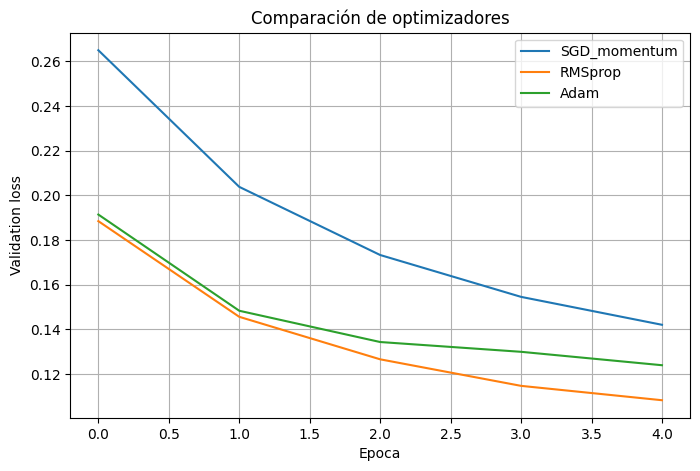

In [27]:
# ============================================================
# Paso 11. Comparar visualmente Validation Loss
# ============================================================
# Se superponen las curvas de pérdida en Dev de los tres optimizadores.
# Qué observar:
#   - ¿Cuál reduce la pérdida de forma más estable?
#   - ¿Alguno muestra picos o saltos bruscos?
#   - ¿La brecha Train–Dev cambia entre optimizadores?

plt.figure(figsize=(8, 5))
for nombre, historia in historias_opt.items():
    plt.plot(historia.history["val_loss"], label=nombre)

plt.xlabel("Epoca")
plt.ylabel("Validation loss")
plt.title("Comparación de optimizadores")
plt.legend()
plt.grid(True)
plt.show()

In [28]:
# ============================================================
# Paso 12. Explorar el Learning Rate de Adam
# ============================================================
# Se prueban tres valores de learning rate:
#   - 0.0001 → paso pequeño, aprendizaje lento
#   - 0.001  → paso intermedio, suele ser buen punto de partida
#   - 0.01   → paso grande, puede oscilar o empeorar entre épocas

learning_rates = [0.0001, 0.001, 0.01]
resultados_lr = []

for lr in learning_rates:
    keras.backend.clear_session()
    tf.random.set_seed(SEED)

    modelo = crear_modelo_experimento(
        keras.optimizers.Adam(learning_rate=lr)
    )

    historia = modelo.fit(
        x_train, y_train,
        validation_data=(x_dev, y_dev),
        epochs=3,
        batch_size=64,
        verbose=0
    )

    resultados_lr.append({
        "learning_rate": lr,
        "train_accuracy": historia.history["accuracy"][-1],
        "dev_accuracy": historia.history["val_accuracy"][-1],
        "dev_loss": historia.history["val_loss"][-1]
    })

display(pd.DataFrame(resultados_lr))

,learning_rate,train_accuracy,dev_accuracy,dev_loss
0,0.0001,0.921188,0.926500,0.272565
1,0.0010,0.967667,0.959917,0.134384
2,0.0100,0.967938,0.959583,0.179393


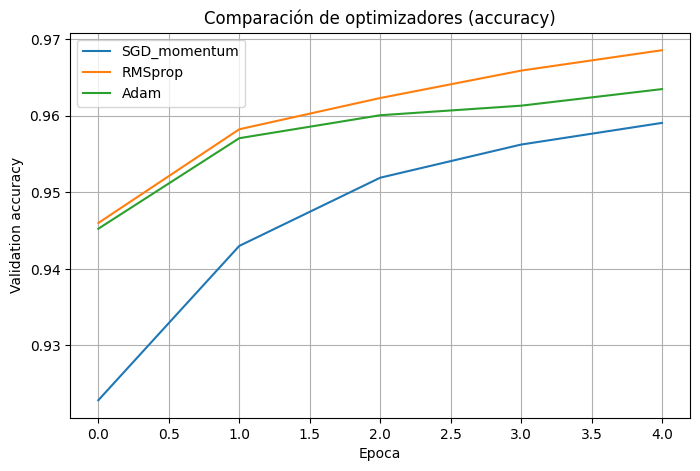

In [29]:
# ============================================================
# Curvas de Validation Accuracy por optimizador
# ============================================================
# Complementa el Paso 11: además de la pérdida, conviene ver
# cómo evoluciona la accuracy en Dev para cada optimizador.

plt.figure(figsize=(8, 5))
for nombre, historia in historias_opt.items():
    plt.plot(historia.history["val_accuracy"], label=nombre)

plt.xlabel("Epoca")
plt.ylabel("Validation accuracy")
plt.title("Comparación de optimizadores (accuracy)")
plt.legend()
plt.grid(True)
plt.show()

# Redes Neuronales III — Laboratorio C
## Regularización y overfitting (Dropout + L2 + Early Stopping)

**Objetivo:** hacer visible el overfitting usando una muestra estratificada
de Train (12 000 ejemplos) y una red más grande, y comparar contra un modelo
regularizado con Dropout(0.30), L2(1e-4) y Early Stopping.

**Entregables:**
- Curvas Train vs Dev del modelo sin regularización
- Curvas Train vs Dev del modelo regularizado
- Comparación de ambas pérdidas en una sola gráfica
- Número de épocas ejecutadas con Early Stopping
- Evaluación en Dev de ambos modelos
- Análisis escrito: ¿cambió la brecha Train–Dev?

In [30]:
# ============================================================
# Paso 13. Crear una muestra para el experimento
# ============================================================
# Se toma una muestra estratificada de 12 000 ejemplos de Train.
# La muestra se usa SOLO para el experimento de regularización.
# Al reducir Train y aumentar la capacidad de la red, el overfitting
# se hace visible y la diferencia entre memorizar y generalizar queda clara.

x_train_reg, _, y_train_reg, _ = train_test_split(
    x_train, y_train,
    train_size=12000,
    random_state=SEED,
    stratify=y_train
)

print("Muestra:", x_train_reg.shape, y_train_reg.shape)

Muestra: (12000, 28, 28) (12000,)


In [31]:
# ============================================================
# Paso 14. Modelo sin regularización
# ============================================================
# Red más grande (512 y 256 neuronas) sin ninguna técnica de regularización.
# Se espera una brecha Train–Dev creciente: señal típica de overfitting.

def crear_modelo_sin_regularizacion():
    modelo = keras.Sequential([
        layers.Input(shape=(28, 28)),
        layers.Flatten(),
        layers.Dense(512, activation="relu"),
        layers.Dense(256, activation="relu"),
        layers.Dense(10, activation="softmax")
    ])
    modelo.compile(
        optimizer=keras.optimizers.Adam(0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return modelo

modelo_sin_reg = crear_modelo_sin_regularizacion()
hist_sin_reg = modelo_sin_reg.fit(
    x_train_reg, y_train_reg,
    validation_data=(x_dev, y_dev),
    epochs=15,
    batch_size=64,
    verbose=0
)

In [32]:
# ============================================================
# Paso 15. Modelo con L2, Dropout y Early Stopping
# ============================================================
# Se aplican tres técnicas de regularización:
#   - L2 (kernel_regularizer) para penalizar pesos grandes.
#   - Dropout(0.30) para desactivar unidades durante el entrenamiento.
#   - Early Stopping con patience=2 y restore_best_weights=True
#     para detener el entrenamiento cuando val_loss deja de mejorar.

def crear_modelo_regularizado():
    modelo = keras.Sequential([
        layers.Input(shape=(28, 28)),
        layers.Flatten(),
        layers.Dense(
            512, activation="relu",
            kernel_regularizer=regularizers.l2(1e-4)           ),
        layers.Dropout(0.30),
        layers.Dense(
            256, activation="relu",
            kernel_regularizer=regularizers.l2(1e-4)           ),
        layers.Dropout(0.30),
        layers.Dense(10, activation="softmax")
    ])
    modelo.compile(
        optimizer=keras.optimizers.Adam(0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return modelo

parada_temprana = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

modelo_reg = crear_modelo_regularizado()
hist_reg = modelo_reg.fit(
    x_train_reg, y_train_reg,
    validation_data=(x_dev, y_dev),
    epochs=20,
    batch_size=64,
    callbacks=[parada_temprana],
    verbose=0
)

# Aunque pedimos 20 épocas, Early Stopping puede detenerse antes.
print("Épocas ejecutadas:", len(hist_reg.history["loss"]))

Épocas ejecutadas: 8


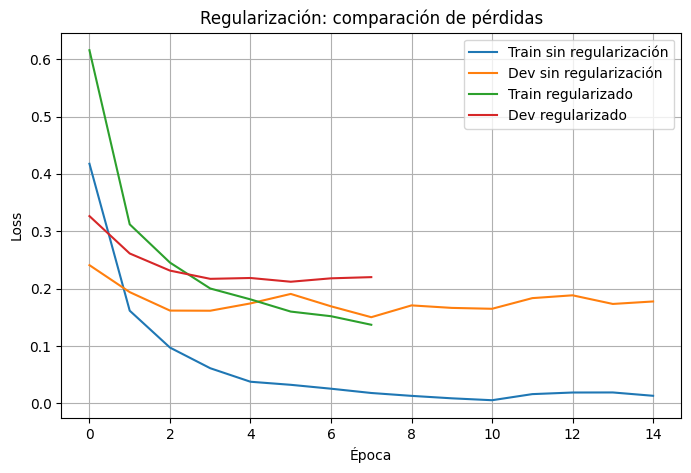

In [33]:
# ============================================================
# Paso 16. Comparar curvas
# ============================================================
# Se superponen las curvas de Train y Dev de ambos modelos.
# Qué observar:
#   - Sin regularización: Train sigue bajando, Dev se estanca o sube
#     → señal de overfitting.
#   - Con regularización: la brecha Train–Dev debería ser menor.

plt.figure(figsize=(8, 5))
plt.plot(hist_sin_reg.history["loss"], label="Train sin regularización")
plt.plot(hist_sin_reg.history["val_loss"], label="Dev sin regularización")
plt.plot(hist_reg.history["loss"], label="Train regularizado")
plt.plot(hist_reg.history["val_loss"], label="Dev regularizado")
plt.xlabel("Época")
plt.ylabel("Loss")
plt.title("Regularización: comparación de pérdidas")
plt.legend()
plt.grid(True)
plt.show()

In [34]:
# ============================================================
# Paso 17. Evaluar ambos modelos en Dev
# ============================================================
# La regularización puede reducir un poco la accuracy de Train
# y aun así mejorar la generalización. No debe evaluarse mirando
# solo Train: hay que mirar Dev y, al final, Test.

dev_sin_reg = modelo_sin_reg.evaluate(x_dev, y_dev, verbose=0)
dev_reg = modelo_reg.evaluate(x_dev, y_dev, verbose=0)

print("Sin regularización - dev loss/accuracy:", dev_sin_reg)
print("Regularizado - dev loss/accuracy:", dev_reg)

Sin regularización - dev loss/accuracy: [0.1776280701160431, 0.9617499709129333]
Regularizado - dev loss/accuracy: [0.21202661097049713, 0.9633333086967468]


In [35]:
# ============================================================
# Reentrenar el modelo regularizado con todo Train
# ============================================================
# Motivo: el Laboratorio D usa Test para la evaluación final.
# Conviene que ese modelo final haya visto TODO el Train disponible,
# no solo la muestra de 12 000 usada para el experimento de overfitting.
# Este paso NO es parte del documento original; se deja como opcional.

keras.backend.clear_session()
tf.random.set_seed(SEED)

modelo_reg_full = crear_modelo_regularizado()

parada_temprana_full = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

hist_reg_full = modelo_reg_full.fit(
    x_train, y_train,
    validation_data=(x_dev, y_dev),
    epochs=20,
    batch_size=64,
    callbacks=[parada_temprana_full],
    verbose=0
)

print("Épocas ejecutadas (Train completo):", len(hist_reg_full.history["loss"]))
print("Dev accuracy final:", hist_reg_full.history["val_accuracy"][-1])

Épocas ejecutadas (Train completo): 5
Dev accuracy final: 0.9714166522026062


# Redes Neuronales III — Laboratorio D
## Métricas de evaluación (Accuracy, Precision, Recall, F1 y matriz de confusión)

**Objetivo:** evaluar el modelo final en Test usando métricas más completas
que Accuracy. A partir de este punto, Test se reserva para la evaluación final
y el modelo no debe seguir ajustándose con base en estos resultados.

**Entregables:**
- Tabla de métricas (Accuracy, Precision macro, Recall macro, F1 macro)
- Reporte de clasificación por clase
- Matriz de confusión
- Identificación de la confusión más frecuente
- Al menos un ejemplo mal clasificado visualizado

In [36]:
# ============================================================
# Paso 18. Generar predicciones
# ============================================================
# Se obtienen las probabilidades por clase y se elige la de mayor
# valor con argmax. Se usa el modelo regularizado entrenado en el Lab C.

probabilidades_test = modelo_reg.predict(x_test, verbose=0)   y_pred = np.argmax(probabilidades_test, axis=1)

print("Primeras predicciones:", y_pred[:20])
print("Primeras clases reales:", y_test[:20])

Primeras predicciones: [7 2 1 0 4 1 4 9 6 9 0 6 9 0 1 5 9 7 3 4]
Primeras clases reales: [7 2 1 0 4 1 4 9 5 9 0 6 9 0 1 5 9 7 3 4]


In [37]:
# ============================================================
# Paso 19. Accuracy, Precision, Recall y F1
# ============================================================
# Se calculan las métricas con promedio macro, que da el mismo peso
# a cada dígito. Así, una clase con menos ejemplos no queda diluida.

accuracy = accuracy_score(y_test, y_pred)
precision_macro = precision_score(
    y_test, y_pred, average="macro", zero_division=0
)
recall_macro = recall_score(
    y_test, y_pred, average="macro", zero_division=0
)
f1_macro = f1_score(
    y_test, y_pred, average="macro", zero_division=0
)

print("Accuracy:", round(accuracy, 4))
print("Precision macro:", round(precision_macro, 4))
print("Recall macro:", round(recall_macro, 4))
print("F1 macro:", round(f1_macro, 4))

Accuracy: 0.9634
Precision macro: 0.9631
Recall macro: 0.9632
F1 macro: 0.963


In [38]:
# ============================================================
# Paso 20. Crear una tabla de métricas
# ============================================================
# Esta tabla debe aparecer en el documento técnico final.

metricas = pd.DataFrame({
    "metrica": ["Accuracy", "Precision macro", "Recall macro", "F1 macro"],
    "resultado": [accuracy, precision_macro, recall_macro, f1_macro]
})
display(metricas)   

,metrica,resultado
0,Accuracy,0.963400
1,Precision macro,0.963129
2,Recall macro,0.963235
3,F1 macro,0.963026


In [39]:
# ============================================================
# Paso 21. Reporte por cada dígito
# ============================================================
# El estudiante debe identificar al menos una clase cuyo Precision,
# Recall o F1 sea inferior al promedio y proponer una interpretación.

print(
    classification_report(
        y_test, y_pred, digits=4, zero_division=0
    )
)

              precision    recall  f1-score   support

           0     0.9699    0.9878    0.9788       980
           1     0.9876    0.9859    0.9868      1135
           2     0.9897    0.9302    0.9590      1032
           3     0.9449    0.9673    0.9560      1010
           4     0.9476    0.9756    0.9614       982
           5     0.9574    0.9574    0.9574       892
           6     0.9597    0.9697    0.9647       958
           7     0.9668    0.9621    0.9644      1028
           8     0.9433    0.9559    0.9495       974
           9     0.9644    0.9405    0.9523      1009

    accuracy                         0.9634     10000
   macro avg     0.9631    0.9632    0.9630     10000
weighted avg     0.9637    0.9634    0.9634     10000



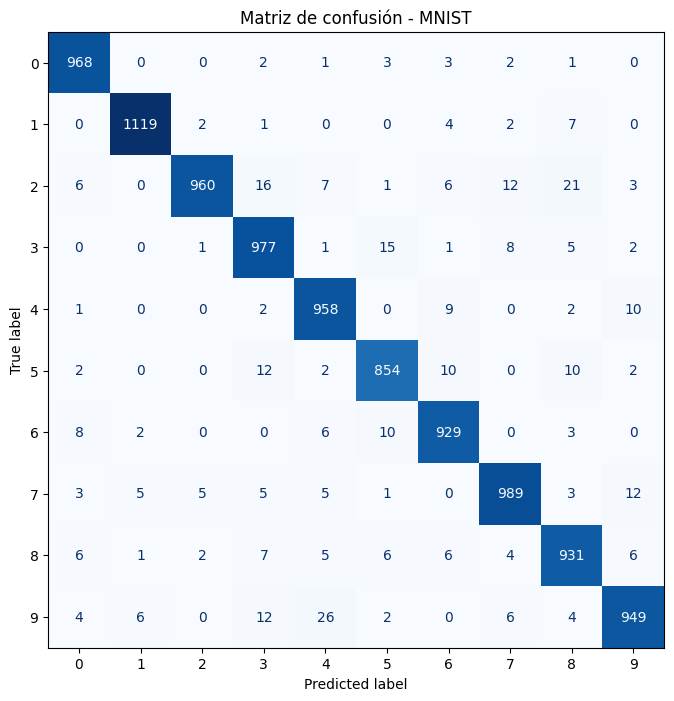

In [40]:
# ============================================================
# Paso 22. Matriz de confusión
# ============================================================
# La diagonal representa aciertos. Las posiciones fuera de la diagonal
# muestran en qué clase real se produjo una predicción equivocada.

cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(8, 8))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,       display_labels=np.arange(10)
)
disp.plot(ax=ax, cmap="Blues", colorbar=False)
plt.title("Matriz de confusión - MNIST")
plt.show()

In [41]:
# ============================================================
# Paso 23. Encontrar la confusión más frecuente
# ============================================================
# Se anula la diagonal (aciertos) y se busca el par (real, predicho)
# con mayor conteo de errores.

cm_errores = cm.copy()
np.fill_diagonal(cm_errores, 0)

real_confundido, predicho_como = np.unravel_index(
    np.argmax(cm_errores), cm_errores.shape
)

cantidad = cm_errores[real_confundido, predicho_como]

print(
    f"La confusión más frecuente fue: "
    f"{real_confundido} clasificado como {predicho_como} "
    f"({cantidad} veces)"
)

La confusión más frecuente fue: 9 clasificado como 4 (26 veces)


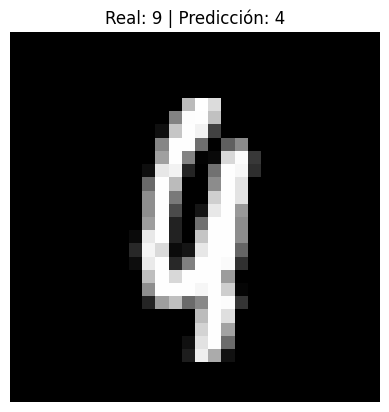

In [42]:
# ============================================================
# Paso 24. Visualizar un error real
# ============================================================
# El objetivo no es esconder los errores. Un análisis profesional
# muestra dónde se equivoca el modelo y qué podría mejorarse.

indices = np.where(
    (y_test == real_confundido) & (y_pred == predicho_como)
)[0]

if len(indices) > 0:
    idx = indices[0]
    plt.imshow(x_test[idx], cmap="gray")
    plt.title(
        f"Real: {y_test[idx]} | Predicción: {y_pred[idx]}"
    )       plt.axis("off")
    plt.show()

# Redes Neuronales III — Laboratorio E
## Bias, variance y tradeoff

**Objetivo:** diagnosticar el comportamiento del modelo observando
conjuntamente Train y Dev. No se debe asignar la etiqueta bias o variance
por una sola cifra.

**Entregables:**
- Modelo intencionalmente pequeño entrenado
- Tabla de diagnóstico Train-Dev para los tres modelos
- Interpretación escrita: ¿bias, variance o equilibrio?

In [43]:
# ============================================================
# Paso 25. Modelo intencionadamente pequeño
# ============================================================
# Red con solo 16 neuronas en la capa oculta, entrenada por 2 épocas.
# Se espera que tenga dificultades para capturar el patrón:
# es decir, bias alto / underfitting.
#
# El diagnóstico se realiza observando conjuntamente Train y Dev.
# No se debe asignar la etiqueta bias o variance por una sola cifra.

modelo_pequeno = keras.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(16, activation="relu"),
    layers.Dense(10, activation="softmax")
])
modelo_pequeno.compile(
    optimizer=keras.optimizers.Adam(0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"])

hist_pequeno = modelo_pequeno.fit(
    x_train, y_train,
    validation_data=(x_dev, y_dev),
    epochs=2,
    batch_size=64,
    verbose=0
)

In [44]:
# ============================================================
# Paso 26. Resumir la brecha Train-Dev
# ============================================================
# Se construye una tabla comparativa con los tres modelos:
#   - Pequeño        → se espera bias alto / underfitting
#   - Sin regul.     → se espera variance alta / overfitting
#   - Regularizado   → se espera mejor equilibrio
# La lectura se hace con Train y Dev juntos, nunca con uno solo.

def resumen_historia(nombre, historia):
    train_acc = historia.history["accuracy"][-1]
    dev_acc = historia.history["val_accuracy"][-1]
    return {
        "modelo": nombre,
        "train_accuracy": train_acc,
        "dev_accuracy": dev_acc,
        "brecha_train_dev": train_acc - dev_acc
    }

tabla_diagnostico = pd.DataFrame([
    resumen_historia("Pequeño", hist_pequeno),
    resumen_historia("Sin regularización", hist_sin_reg),
    resumen_historia("Regularizado", hist_reg)
])

display(tabla_diagnostico)

,modelo,train_accuracy,dev_accuracy,brecha_train_dev
0,Pequeño,0.921313,0.920250,0.001063
1,Sin regularización,0.996667,0.961750,0.034917
2,Regularizado,0.981833,0.963167,0.018667


In [45]:
# ============================================================
# Guía de lectura del diagnóstico
# ============================================================
# Tabla de referencia para interpretar la tabla_diagnostico:
#
# | Patrón                              | Lectura posible       | Acción                                              |
# |-------------------------------------|-----------------------|-----------------------------------------------------|
# | Train y Dev bajos                   | Bias / underfitting   | Más capacidad, más entrenamiento o mejores features |
# | Train alto y Dev bastante menor     | Variance / overfitting| Regularización, más datos, simplificar, Early Stop  |
# | Train y Dev altos y cercanos        | Mejor equilibrio      | Confirmar con Test y métricas por clase             |
# | Tradeoff                            | Reducir bias puede    | Se busca equilibrio, no una cifra aislada           |
# |                                     | aumentar variance     |                                                     |

print("Guía de lectura:")
print(" - Train y Dev bajos → bias / underfitting")
print(" - Train alto y Dev bastante menor → variance / overfitting")
print(" - Train y Dev altos y cercanos → mejor equilibrio")

Guía de lectura:
 - Train y Dev bajos → bias / underfitting
 - Train alto y Dev bastante menor → variance / overfitting
 - Train y Dev altos y cercanos → mejor equilibrio


# Redes Neuronales III — Laboratorio F (opcional)
## PyTorch: mismo problema, mismo modelo, distinto framework

**Objetivo:** reproducir la misma lógica del modelo regularizado (Dropout + L2)
con PyTorch, para comparar cómo cambia el ciclo de entrenamiento respecto a Keras.

**Entregables:**
- Definición del modelo con Dropout y L2 (weight_decay)
- Loss y accuracy reportados
- Comparación conceptual con TensorFlow/Keras

In [46]:
# ============================================================
# Paso 27. Modelo PyTorch con Dropout y L2
# ============================================================
# Equivalencias con Keras:
#   layers.Dropout(0.30)      ↔  nn.Dropout(0.30)
#   regularizers.l2(1e-4)     ↔  weight_decay=1e-4 en el optimizador
#   optimizer=Adam(...)       ↔  optim.Adam(...)
#   model.fit(...)            ↔  bucle "for" explícito (ver siguiente celda)
#   EarlyStopping callback    ↔  control manual o librería auxiliar

import torch
import torch.nn as nn
import torch.optim as optim

class RedMNISTRegularizada(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(784, 256)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.30)
        self.fc2 = nn.Linear(256, 10)

    def forward(self, x):
        x = self.flatten(x)
        x = self.fc1(x)
        x = self.relu(x)
        x = self.dropout(x)
        return self.fc2(x)

modelo_torch = RedMNISTRegularizada()
criterio = nn.CrossEntropyLoss()
optimizador = optim.Adam(
    modelo_torch.parameters(),
    lr=0.001,
    weight_decay=1e-4       )

print(modelo_torch)

RedMNISTRegularizada(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=784, out_features=256, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.3, inplace=False)
  (fc2): Linear(in_features=256, out_features=10, bias=True)
)


In [47]:
# ============================================================
# Bucle de entrenamiento y validación en PyTorch
# ============================================================
# En Keras, model.fit() encapsula todo. En PyTorch el ciclo es explícito:
#   1) forward  → obtener salidas
#   2) loss     → calcular error
#   3) zero_grad → limpiar gradientes
#   4) backward → calcular gradientes
#   5) step     → actualizar parámetros
# Este bucle es necesario para reportar "Loss y accuracy" como pide la evidencia.

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", device)

# Convertir a tensores de PyTorch
def a_tensor(x, y):
    x_t = torch.tensor(x, dtype=torch.float32).to(device)
    y_t = torch.tensor(y, dtype=torch.long).to(device)
    return x_t, y_t

x_train_t, y_train_t = a_tensor(x_train, y_train)
x_dev_t,   y_dev_t   = a_tensor(x_dev,   y_dev)
x_test_t,  y_test_t  = a_tensor(x_test,  y_test)

modelo_torch = modelo_torch.to(device)

EPOCHS_TORCH = 5
BATCH_SIZE_TORCH = 64

from torch.utils.data import TensorDataset, DataLoader

train_ds = TensorDataset(x_train_t, y_train_t)
train_dl = DataLoader(train_ds, batch_size=BATCH_SIZE_TORCH, shuffle=True)

hist_torch = {"train_loss": [], "train_acc": [], "dev_loss": [], "dev_acc": []}

for epoch in range(EPOCHS_TORCH):
    # --- Entrenamiento ---
    modelo_torch.train()
    loss_acum, aciertos, total = 0.0, 0, 0

    for xb, yb in train_dl:
        optimizador.zero_grad()
        salidas = modelo_torch(xb)
        loss = criterio(salidas, yb)
        loss.backward()
        optimizador.step()

        loss_acum += loss.item() * xb.size(0)
        preds = salidas.argmax(dim=1)
        aciertos += (preds == yb).sum().item()
        total += xb.size(0)

    train_loss = loss_acum / total
    train_acc  = aciertos / total

    # --- Validación ---
    modelo_torch.eval()
    with torch.no_grad():
        salidas_dev = modelo_torch(x_dev_t)
        dev_loss = criterio(salidas_dev, y_dev_t).item()
        preds_dev = salidas_dev.argmax(dim=1)
        dev_acc = (preds_dev == y_dev_t).float().mean().item()

    hist_torch["train_loss"].append(train_loss)
    hist_torch["train_acc"].append(train_acc)
    hist_torch["dev_loss"].append(dev_loss)
    hist_torch["dev_acc"].append(dev_acc)

    print(f"Época {epoch+1}/{EPOCHS_TORCH} | "
          f"train_loss={train_loss:.4f} train_acc={train_acc:.4f} | "
          f"dev_loss={dev_loss:.4f} dev_acc={dev_acc:.4f}")

Dispositivo: cpu
Época 1/5 | train_loss=0.3709 train_acc=0.8960 | dev_loss=0.1945 dev_acc=0.9448
Época 2/5 | train_loss=0.1789 train_acc=0.9481 | dev_loss=0.1374 dev_acc=0.9599
Época 3/5 | train_loss=0.1326 train_acc=0.9611 | dev_loss=0.1166 dev_acc=0.9652
Época 4/5 | train_loss=0.1076 train_acc=0.9672 | dev_loss=0.0993 dev_acc=0.9715
Época 5/5 | train_loss=0.0913 train_acc=0.9722 | dev_loss=0.0905 dev_acc=0.9737


In [48]:
# ============================================================
# Evaluación final en Dev con PyTorch
# ============================================================
# Se reporta el desempeño final del modelo regularizado en Dev
# para compararlo con la versión de Keras.

modelo_torch.eval()
with torch.no_grad():
    salidas_dev = modelo_torch(x_dev_t)
    dev_loss_final = criterio(salidas_dev, y_dev_t).item()
    preds_dev = salidas_dev.argmax(dim=1)
    dev_acc_final = (preds_dev == y_dev_t).float().mean().item()

print(f"PyTorch - Dev loss: {dev_loss_final:.4f}")
print(f"PyTorch - Dev accuracy: {dev_acc_final:.4f}")

PyTorch - Dev loss: 0.0905
PyTorch - Dev accuracy: 0.9737


In [49]:
# ============================================================
# Comparación conceptual: TensorFlow/Keras ↔ PyTorch
# ============================================================
# | TensorFlow/Keras                | PyTorch                  | Idea común                        |
# |---------------------------------|--------------------------|-----------------------------------|
# | layers.Dropout(0.30)            | nn.Dropout(0.30)         | Desactivar unidades durante Train |
# | regularizers.l2(1e-4)           | weight_decay=1e-4        | Regularización L2                 |
# | optimizer=Adam(...)             | optim.Adam(...)          | Actualizar parámetros             |
# | model.fit(...)                  | for explícito            | Ciclo de entrenamiento            |
# | EarlyStopping callback          | Control manual           | Detener según validación          |

import pandas as pd

comparativa = pd.DataFrame([
    {"framework": "TensorFlow/Keras", "dev_loss": None, "dev_accuracy": None},
    {"framework": "PyTorch",          "dev_loss": round(dev_loss_final, 4),
                                       "dev_accuracy": round(dev_acc_final, 4)},
])

# Si ejecutaste el Lab C, puedes reemplazar los None por los valores de
# dev_reg = modelo_reg.evaluate(x_dev, y_dev, verbose=0) para comparar lado a lado.

display(comparativa)

,framework,dev_loss,dev_accuracy
0,TensorFlow/Keras,NaN,NaN
1,PyTorch,0.0905,0.9737
